In [ ]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
from copy import deepcopy
import multiprocessing as mp
import logging
import random
from itertools import cycle
import os
from functools import partial

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from networkx import number_weakly_connected_components
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.Simulators.GNWSimRunner import GNWSimRunner
from halcyon.Simulators.NoiseLevel import NoiseLevel
from halcyon.Simulators.SimulationResult import SimulationResult

from halcyon.Models.PhoenixModels import PhoenixAddAndProdLayers
from halcyon.Models.BaseLineModels import AlwaysDerivativeZero
from halcyon.Models.MechanisticModel import PyTorchODE
from halcyon.Models.HybridModel import HybridModel

from halcyon.Models.ModelRunner import ModelRunner, run_training_job
from halcyon.Models.Losses import MSELossPlusMachineLearningL2

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

Check if MLFlow connects correctly

In [2]:
print(os.getenv("MLFLOW_TRACKING_URI"))

https://mlflow.cropresilience.org


In [3]:
[f"{experiment.name=}" for experiment in mlflow.search_experiments()]
mlflow.set_experiment("Halcyon sandbox experiment")
mlflow.set_experiment_tag("Tool name", "HALCYON") 

# Input data

## Simulating

In [ ]:
nr_genes_list = [20]
nr_modules_list = [4]
sparsity_list = [0.1]
out_path = Path("../data/hybrid_model_with_noise") 
keep_self_interactions = False

sim_outputs: list[SimulationResult] = []
for nr_genes in nr_genes_list: 
    for nr_modules in nr_modules_list: 
        for sparsity in sparsity_list: 
            gnw_sim = GNWSimRunner(
                settings_path=Path("../setting_files/gnw_testing_runs_settings.txt"),
            )
            generated_data_path = out_path / f"genes_{nr_genes}_modules_{nr_modules}_sparsity_{sparsity}"
            generated_data_path.mkdir(parents=True, exist_ok=True)
            network_name = 'my_network'
            sim_output = gnw_sim.run_simulation(
                n_genes=nr_genes,
                sparsity=sparsity,
                num_modules=nr_modules,
                network_name=network_name,
                output_path=generated_data_path,
                keep_self_interactions=keep_self_interactions,
                noise_level=NoiseLevel.ALLNOISE,
            )

            # sim_output.network.do_clustering()

            # print(number_weakly_connected_components(sim_output.network._graph))

            # sim_output.network.plot()
            # plt.show()

            sim_output.save_to_pkl(generated_data_path / "simulation_result.pkl")
            
            with mlflow.start_run(run_name=f"dataset_genes{nr_genes}_sparsity{sparsity}_nr_modules{nr_modules}_noise{NoiseLevel.ALLNOISE.name}"):
                mlflow.set_tag("run_type", "dataset")
                mlflow.log_params({
                    "nr_genes": nr_genes,
                    "sparsity": sparsity,
                    "num_modules": nr_modules,
                    "noise_level": NoiseLevel.ALLNOISE.name,
                    "seed": seed,
                })

                mlflow.log_artifacts(generated_data_path, artifact_path="dataset")

## Downloading data from MLFlow

In [4]:
sim_run_id_to_use = "72e5027402c2484db8acade9e9872170"  
run = mlflow.get_run(sim_run_id_to_use)

params = run.data.params
print(params)

{'nr_genes': '20', 'sparsity': '0.1', 'num_modules': '4', 'noise_level': 'ALLNOISE', 'seed': '174'}


In [5]:
ml_flow_download_path = mlflow.artifacts.download_artifacts(run_id=sim_run_id_to_use, artifact_path="dataset")
sim_output = SimulationResult.load_from_pkl(Path(ml_flow_download_path) / "simulation_result.pkl")

2026-02-12 14:50:56,234 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-02-12 14:50:56,239 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-02-12 14:50:56,244 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-02-12 14:50:56,248 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-02-12 14:50:56,272 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-02-12 14:50:56,278 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-02-12 14:50:56,281 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-02-12 14:50:56,293 - WARNING - Connection p

## Convert sim output into datasets for use with the trainer object

In [6]:
# From sim output to datasets
single_ko_dataset, double_ko_dataset, time_scaling_factor = sim_output.create_datasets()
dataset_dict = {
    "single_ko": single_ko_dataset,
    "double_ko": double_ko_dataset,}

# Trainers (with different models) creation

In [7]:
train_jobs : list[ModelRunner] = []
device = cycle(['cuda:0', 'cuda:1'])

## Mech model

Assigning only one cluster of genes to this MM

1


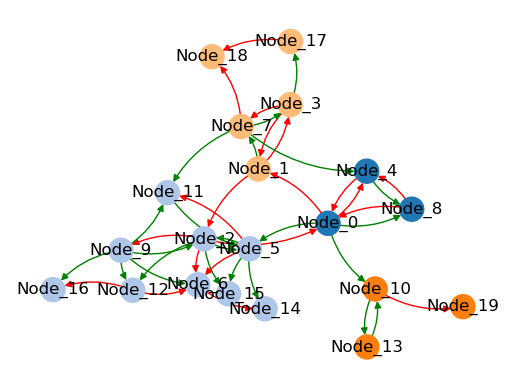

In [8]:
sim_output.network.do_clustering()

print(number_weakly_connected_components(sim_output.network._graph))

sim_output.network.plot()
plt.show()

In [9]:
node_that_should_be_in_model = 'Node_18'
for i, module in enumerate(sim_output.network._clustering):
    if node_that_should_be_in_model in module:
        print('Module:', i)
        print('Size:', len(module))
        genes_to_select = list(sim_output.network._clustering[i])
        break

Module: 3
Size: 5


Generate MM from this subset

In [ ]:
mm = PyTorchODE.from_sbml(sim_output.data_path / 'my_network.xml',
                           condition_names=[], from_gnw=True, device=next(device))
# Select only genes from specific module and set timescaler
mm.select_genes(genes_to_select, 
                goldstandard_signed_file_for_expression_substitution = sim_output.data_path / f'{sim_output.network_name}_goldstandard_signed.tsv')
mm.set_timescaler(time_scaling_factor)

print(mm.modelled_gene_labels)

# Creating MM trainer even though it cannot be trained
mm_trainer = ModelRunner(
    mm,
    nr_epochs=0,
    batch_size=32,
)

train_jobs.append(mm_trainer)

2026-02-12 14:51:27,730 - INFO - Loading SBML model from: /tmp/tmpfag4hb41/dataset/my_network.xml


['Node_1', 'Node_18', 'Node_17', 'Node_3', 'Node_7']


## ML and Hybrid model

In [ ]:
for hidden_size in [10, 20]:
    for do_only_pos in [True]:        
        ml_model = PhoenixAddAndProdLayers(
                    modelled_gene_labels=single_ko_dataset.genes,
                    hidden_size=hidden_size,
                    condition_names=single_ko_dataset.all_environments,
                    synthesis_only_positive=do_only_pos,
                    device=next(device)
            )

        # Create hybrid model with MM and with add and prod
        hybrid_model = HybridModel(deepcopy(mm), deepcopy(ml_model), device=next(device))
        for model in [ml_model, hybrid_model]:
            # my_loss = MSELossPlusMachineLearningL2(lambda_param=0.5)
            model_runner = ModelRunner(
                model = model,
                batch_size=32,
                nr_epochs=5,
                optimizer_kwargs = {'lr': 0.1}
            )
            train_jobs.append(model_runner)

## Baseline model (always derivative of 0)

In [ ]:
baseline_model = AlwaysDerivativeZero(
    modelled_gene_labels=single_ko_dataset.genes,
    condition_names=single_ko_dataset.all_environments
    )

baseline_trainer = ModelRunner(
    baseline_model,
    batch_size=8,
    nr_epochs=0,
)
train_jobs.append(baseline_trainer)

2026-02-12 14:52:19,675 - INFO - Using GPU: Tesla T4 (compute capability 7.5)


In [13]:
for job in train_jobs:
    print(job)
    print()

Modelrunner (Model=PyTorchODE with hyperparams: [],
 optimizer=Adam,
 optimizer_kwargs={},
 nr_epochs=0,
 batch_size=32
)

Modelrunner (Model=PhoenixAddAndProdLayers with hyperparams: ['device=cuda:1', 'hidden_size=10', 'synthesis_only_positive=True'],
 optimizer=Adam,
 optimizer_kwargs={'lr': 0.1},
 nr_epochs=5,
 batch_size=32
)

Modelrunner (Model=HybridModel with hyperparams: ['device=cuda:0', 'hidden_size=10', 'synthesis_only_positive=True'],
 optimizer=Adam,
 optimizer_kwargs={'lr': 0.1},
 nr_epochs=5,
 batch_size=32
)

Modelrunner (Model=PhoenixAddAndProdLayers with hyperparams: ['device=cuda:1', 'hidden_size=20', 'synthesis_only_positive=True'],
 optimizer=Adam,
 optimizer_kwargs={'lr': 0.1},
 nr_epochs=5,
 batch_size=32
)

Modelrunner (Model=HybridModel with hyperparams: ['device=cuda:0', 'hidden_size=20', 'synthesis_only_positive=True'],
 optimizer=Adam,
 optimizer_kwargs={'lr': 0.1},
 nr_epochs=5,
 batch_size=32
)

Modelrunner (Model=AlwaysDerivativeZero with hyperparams: [],

In [14]:
len(train_jobs)

6

In [ ]:
# Old debugging / development bits
# train_jobs[1].nr_epochs = 0
# train_jobs[1].train_and_predict_for_mlflow(dataset_dict, 'single_ko', sim_run_id_to_use)

# Do training

In [ ]:
mp.set_start_method("spawn", force=True)
with mp.Pool(processes=4) as pool:
    pool.map(
        partial(
            run_training_job, 
            dataset_dict=dataset_dict, 
            train_data_key_in_dict="single_ko", 
            simulation_parent_id=sim_run_id_to_use, 
            do_mlflow_model_logging=False,
        ),
        train_jobs
    )

  0%|          | 0/1 [00:00<?, ?it/s]/lustre/BIF/nobackup/noord087/miniforge3/envs/halcyon/lib/python3.10/site-packages/sympy/core/sympify.py:449: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:835.)
  return sympify(float(a))
  0%|          | 0/1 [00:00<?, ?it/s]2026-02-12 14:53:44,971 [SpawnPoolWorker-2] Epoch 0, loss 0.19055064022541046
2026-02-12 14:53:44,972 [SpawnPoolWorker-3] Epoch 0, loss 0.14803704619407654
2026-02-12 14:53:47,147 [SpawnPoolWorker-2] Epoch 1, loss 0.06715937703847885
100%|██████████| 1/1 [00:05<00:00,  5.00s/it]
2026-02-12 14:53:47,518 [SpawnPoolWorker-3] Epoch 1, loss 0.10532092303037643


🏃 View run PyTorchODE at: https://mlflow.cropresilience.org/#/experiments/3/runs/88985511484a4d9e886bb1942b601d2a
🧪 View experiment at: https://mlflow.cropresilience.org/#/experiments/3


/lustre/BIF/nobackup/noord087/miniforge3/envs/halcyon/lib/python3.10/site-packages/sympy/core/sympify.py:449: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:835.)
  return sympify(float(a))
2026-02-12 14:53:49,190 [SpawnPoolWorker-2] Epoch 2, loss 0.059783607721328735
2026-02-12 14:53:49,787 [SpawnPoolWorker-3] Epoch 2, loss 0.04688792675733566
2026-02-12 14:53:51,926 [SpawnPoolWorker-2] Epoch 3, loss 0.05267323926091194
2026-02-12 14:53:53,041 [SpawnPoolWorker-3] Epoch 3, loss 0.0492972806096077
2026-02-12 14:53:54,400 [SpawnPoolWorker-2] Epoch 4, loss 0.05014943331480026
100%|██████████| 1/1 [00:01<00:00,  1.46s/it]
2026-02-12 14:53:57,219 [SpawnPoolWorker-3] Epoch 4, loss 0.03833574801683426
100%|██████████| 1/1 [00:01<00:00,  1.46s/it]
2026-02-12 14:53:59,691 [SpawnPoolWorker-4] Epoch 0, loss 0.14465

🏃 View run PhoenixAddAndProdLayers at: https://mlflow.cropresilience.org/#/experiments/3/runs/b29ea49d059b40438230917a6396ed56
🧪 View experiment at: https://mlflow.cropresilience.org/#/experiments/3


100%|██████████| 3/3 [00:00<00:00,  6.78it/s]


...

🏃 View run PhoenixAddAndProdLayers at: https://mlflow.cropresilience.org/#/experiments/3/runs/785d269b9a304ec39fe3a8dce03d3976
🧪 View experiment at: https://mlflow.cropresilience.org/#/experiments/3


2026-02-12 14:54:13,932 [SpawnPoolWorker-4] Epoch 1, loss 0.05615030974149704
2026-02-12 14:54:22,254 [SpawnPoolWorker-1] Epoch 1, loss 0.09902352094650269
2026-02-12 14:54:28,466 [SpawnPoolWorker-4] Epoch 2, loss 0.05038450285792351
2026-02-12 14:54:39,107 [SpawnPoolWorker-1] Epoch 2, loss 0.042276524007320404
2026-02-12 14:54:43,453 [SpawnPoolWorker-4] Epoch 3, loss 0.044445160776376724
2026-02-12 14:54:56,614 [SpawnPoolWorker-4] Epoch 4, loss 0.04463429003953934
2026-02-12 14:54:57,411 [SpawnPoolWorker-1] Epoch 3, loss 0.04676557332277298
100%|██████████| 1/1 [00:07<00:00,  7.12s/it]


🏃 View run HybridModel at: https://mlflow.cropresilience.org/#/experiments/3/runs/ee74adc450ee4a33b9690f4107602ad7
🧪 View experiment at: https://mlflow.cropresilience.org/#/experiments/3


100%|██████████| 1/1 [00:11<00:00, 11.39s/it]


🏃 View run HybridModel at: https://mlflow.cropresilience.org/#/experiments/3/runs/12c155db659f4bc1b1c470d206e898b1
🧪 View experiment at: https://mlflow.cropresilience.org/#/experiments/3


# All files have now been logged to MLFlow

To see how to process this data further look into the MLFlow loading and plotting notebook(s)